# Quarterly sales review

An agent cleaned the Q3 orders, rebuilt the regional totals and checked the growth rate. Growth is
$g_t = \dfrac{S_t - S_{t-1}}{S_{t-1}}$, where $S_t$ is the revenue of month $t$.

In [1]:
import pandas as pd

orders = pd.read_csv("sales_q3.csv", parse_dates=["date"])
print(f"Loaded {len(orders):,} orders from sales_q3.csv")

Loaded 1,248 orders from sales_q3.csv


## 1. Clean the data

- Drop the 14 test orders.
- Fill missing `discount` with 0.

In [2]:
orders = orders[~orders["is_test"]].fillna({"discount": 0})
orders.head()

,order,date,region,units,price,discount
0,10231,2026-07-01,North,3,129.00,0.00
1,10232,2026-07-01,West,1,899.00,0.10
2,10233,2026-07-02,East,12,19.50,0.00
3,10234,2026-07-02,South,2,249.00,0.05
4,10235,2026-07-03,Central,5,64.90,0.00


## 2. Revenue by region

In [3]:
revenue = (orders.assign(total=orders.units * orders.price * (1 - orders.discount))
                  .groupby("region")["total"].sum().sort_values(ascending=False))
revenue.to_frame()

,total
West,"471,900"
North,"412,300"
East,"356,100"
South,"298,750"
Central,"187,400"


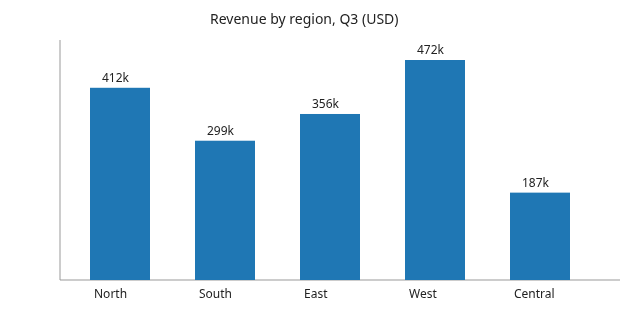

In [4]:
ax = revenue.reindex(["North", "South", "East", "West", "Central"]).plot.bar(title="Revenue by region, Q3 (USD)")
ax.figure.savefig("revenue.png")

## 3. Growth

Average monthly growth over the quarter:

$$\bar g = \frac{1}{n}\sum_{t=1}^{n} \frac{S_t - S_{t-1}}{S_{t-1}} \approx 4.6\%$$

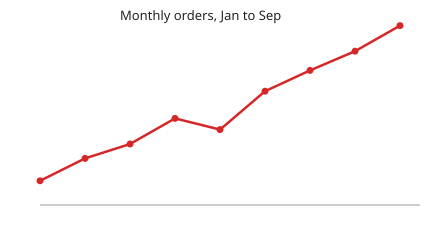

In [5]:
from IPython.display import SVG
SVG(filename="orders_by_month.svg")

## 4. Checks

In [6]:
monthly = orders.resample("M", on="date")["units"].sum()

In [7]:
assert orders["region_code"].notna().all(), "every order needs a region code"

KeyError: 'region_code'

## 5. Next steps

1. Add `region_code` in the export job.
2. Re-run the checks.
3. Share the regional totals with finance.